# One-step pivot: walkthrough of Phases 0–4

This notebook runs what is implemented on `exp/one-step-primitives` up to Phase 4, in the
kinematic simulation (no robot motion anywhere in this notebook). Each section gives the
code, a short explanation, and what changed compared to the previous code.

| Section | Content |
|---|---|
| 0 | Setup, and what changed vs the previous implementation |
| 1 | Scene: cuboid of `tests/rtb.ipynb`, robot base 0.013 m above the table |
| 2 | Phase 2: pivot primitive math (body twist in `{c}`, time scaling, lifting direction) |
| 3 | Phase 3: `ContactQP`, the QP of manuscript Sec. 6 (free rotation / rigid / slack) |
| 4 | Phase 4: executor (screw approach, grasp, pivot) and the free vs rigid vs slack result |
| 5 | Optional: live Swift viewer and replay (`RUN_VIEWER`) |
| 6 | Optional: read-only FER check, then brakes locked (`RUN_HARDWARE`) |
| 7 | Findings so far and next steps |

Kernel: `~/envs/robotics`. The plan and decisions are in `~/pandaSim/pandaSim_handoff/`.

In [1]:
import sys
sys.path = [p for p in sys.path if "/opt/ros" not in p]   # ROS Humble's numpy 1.x would shadow the env

import time
from pathlib import Path
import tempfile

import numpy as np
import matplotlib.pyplot as plt
import spatialmath as sm
import spatialgeometry as sg
from pytransform3d import transformations as pt, rotations as pr

RUN_VIEWER = False      # Section 5: live Swift view in a separate process (opens a browser tab)
RUN_HARDWARE = False    # Section 6: read-only FER check, then locks the brakes (be at the robot)
ROBOT_IP = "172.16.0.2"
BASE_Z = 0.013          # robot mount above the object table in the lab
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__)

numpy 2.2.6


## 0. What changed vs the previous implementation

| Topic | Before | Now | Why |
|---|---|---|---|
| Twist order | `(v, ω)` everywhere (RTB) | `(ω, v)` as in the manuscript (Lynch & Park); RTB rows swapped only where its Jacobian is used | one convention with the paper |
| Pivot twist | `generate_twist_trajectory`: list of twists at a fixed rate, indexed per loop iteration | closed form `𝒱_c(t) = ṡ(t)·[θu_c; θm_c]`, evaluated at the measured time | a slow loop no longer stretches the motion; costs µs |
| Pivot direction | θ flipped if the goal z drops (one generator only) | `lifting_angle`: sign so the object's centre rises | explicit, same everywhere |
| QP | `QPController`: φ treated as a joint (centering pulls φ to 0, damper on φ, manipulability from 8 columns), datasheet speeds 2.62/3.14 rad/s, qpsolvers | `ContactQP`: `eq:qp` with centering, manipulability and damper on θ only, φ free; libfranka 0.8 speed limits × 0.8; rigid mode with 7 outputs; optional slack; quadprog called directly | matches Sec. 6; real FER limits; 0.11 ms per solve |
| Approach | `K·log(T_e⁻¹T_d)` and `smooth_velocity_ramp` scaling the **QP output** | reference is itself a time-scaled screw from the current pose to the grasp, plus small feedback | starts/ends at zero, peak speed chosen in advance, QP stays feasible |
| Loop | Swift `step` (~9 ms) inside the robot loop | one time-indexed loop for sim and FER; Swift in a separate process | 1 kHz possible; viewer cannot block the loop |
| Frames | base offset set on the RTB robot, FK via adapter | `robot.base` applied in every FK (`ets.eval` ignores the base) | object poses stay in the table frame |
| Safety | none in the loop | stop with zero velocity on infeasible QP, external wrench, robot error, timeout; cause logged | hardware |

**Phases 0–1 (done earlier):** shared env `~/envs/robotics` (RTB 1.5, Swift 2.1, panda-py 1.1.1 built for
libfranka 0.8.0); baseline notebooks reproduced (89.9° achieved for a 90° pivot); lazy package
imports (no torch/Genesis/Swift on `import pandaSim`); headless RTB adapter for tests.

## 1. Scene

Same cuboid and grasp as `tests/rtb.ipynb`: box 0.27 × 0.065 × 0.207 m at (0.5, 0, ·) on the table,
top grasp, robot base 0.013 m above the table. The pivot axis and the grasp come from the unchanged
bounding-box planner (`compute_grasp` → `screw_from_bbox`), which works for any object the adapter can bound.

In [2]:
from pandaSim.geometry.utils import create_virtual_panda
from pandaSim.geometry.rtb_adapter import RoboticsToolboxAdapter
from pandaSim.planning.screw_motion_planner import ScrewMotionPlanner
from pandaSim.planning.primitives import lifting_angle, pivot_twist, planned_pose, pose_error_twist, time_scaling

robot = create_virtual_panda()                 # 7 arm joints + virtual bearing joint (about n = y of {c})
robot.base = sm.SE3(0, 0, BASE_Z)
adapter = RoboticsToolboxAdapter({"viewer": None})   # headless: no Swift

BOX = [0.27, 0.065, 0.207]
box = sg.Cuboid(scale=BOX, pose=sm.SE3(0.5, 0.0, BOX[2] / 2), color="blue")
T_w_obj = box.T.copy()
planner = ScrewMotionPlanner(adapter)
T_wd, qs, s_axes = planner.compute_grasp(box, adapter, grasp_height="top", prefer_closer_grasp=True,
                                         gripper_offset=sm.SE3.Rx(np.pi).A)
q_axis, s_axis = qs.reshape(-1, 3)[0], s_axes.reshape(-1, 3)[0]
theta = lifting_angle(q_axis, s_axis, np.pi / 2, T_w_obj[:3, 3])
pivot = dict(q=q_axis, s_axis=s_axis, theta=theta, Tf=5.0)
print("grasp pose of {c}:\n", T_wd)
print("pivot axis point", q_axis, " direction", s_axis, f" signed angle {np.degrees(theta):+.1f} deg")

grasp pose of {c}:
 [[ 1.     0.     0.     0.395]
 [ 0.    -1.    -0.     0.   ]
 [ 0.     0.    -1.     0.187]
 [ 0.     0.     0.     1.   ]]
pivot axis point [0.635 0.    0.   ]  direction [0. 1. 0.]  signed angle +90.0 deg


## 2. Phase 2: pivot primitive (`planning/primitives.py`)

A pivot is a constant screw motion with pitch 0 about the fixed table edge. With the axis
(`u`, point `r`, world) and the contact frame at the grasp `T_wc0 = (R, p)`:

$$u_c = R^\top u,\qquad m_c = \big(R^\top (r-p)\big)\times u_c,\qquad
\mathcal{V}_c(t) = \dot s(t)\begin{bmatrix}\theta\,u_c\\ \theta\,m_c\end{bmatrix}$$

This is the **body twist** of `{c}` (eq. `twist_vec`, `d = 0`); it is constant over the primitive
because `{c}` is attached to the object, so `u_c, m_c` are computed **once** at the grasp.
`time_scaling` gives `(s, ṡ)` in closed form: quintic (default), cubic or linear.

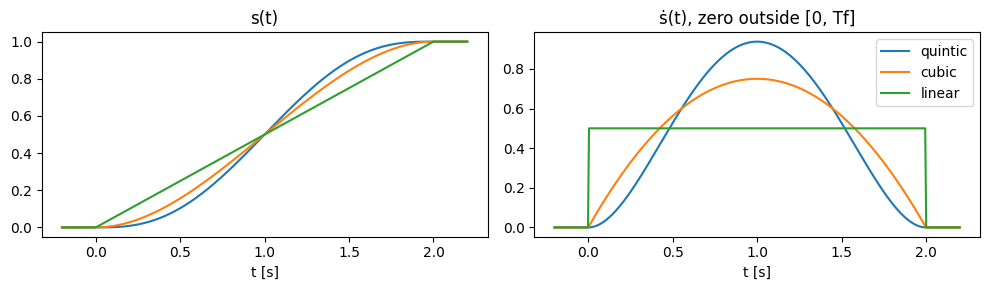

In [3]:
Tf, t = 2.0, np.linspace(-0.2, 2.2, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for m in ("quintic", "cubic", "linear"):
    s, sd = np.array([time_scaling(ti, Tf, m) for ti in t]).T
    ax[0].plot(t, s, label=m); ax[1].plot(t, sd, label=m)
ax[0].set(title="s(t)", xlabel="t [s]"); ax[1].set(title="ṡ(t), zero outside [0, Tf]", xlabel="t [s]"); ax[1].legend()
plt.tight_layout(); plt.show()

In [4]:
V1 = pivot_twist(q_axis, s_axis, theta, T_wd)        # (ω, v) for ṡ = 1
print("constant body twist [θu_c; θm_c] =", V1)

# 1) it is the body twist of the planned pose: log(T(s)^-1 T(s+ds)) / ds
for s in (0.0, 0.5, 0.9):
    Ta, Tb = planned_pose(q_axis, s_axis, theta, T_wd, s), planned_pose(q_axis, s_axis, theta, T_wd, s + 1e-6)
    print(f"s={s}: max |V1 - numerical body twist| = {np.abs(V1 - pt.exponential_coordinates_from_transform(np.linalg.inv(Ta) @ Tb) / 1e-6).max():.1e}")

# 2) same numbers as the old generator (which returns (v, ω) lists at 100 Hz)
old = planner.generate_twist_trajectory(T_wd, q_axis, s_axis, theta, Tf=2.0, time_scaling="q", frequency=100)
new = np.array([time_scaling(ti, 2.0)[1] * V1 for ti in np.linspace(0, 2.0, len(old))])
print("max |old (reordered) - new| =", np.abs(np.c_[old[:, 3:], old[:, :3]] - new).max())

constant body twist [θu_c; θm_c] = [ 0.     -1.5708 -0.      0.2937  0.     -0.377 ]
s=0.0: max |V1 - numerical body twist| = 3.5e-11
s=0.5: max |V1 - numerical body twist| = 1.1e-10
s=0.9: max |V1 - numerical body twist| = 1.9e-10
max |old (reordered) - new| = 6.841749389252527e-15


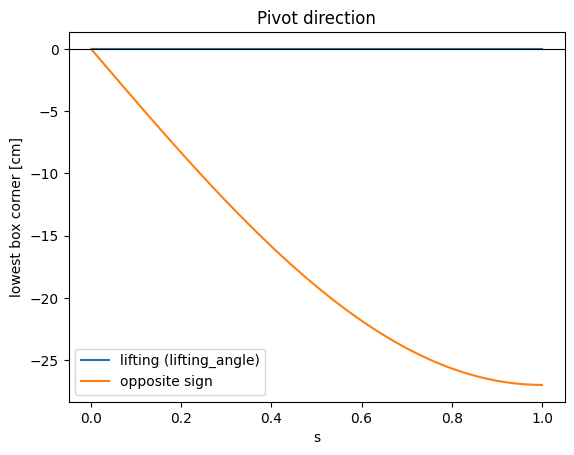

In [5]:
# why the sign matters: lowest box corner over the pivot, lifting vs the opposite direction
corners = np.c_[adapter.get_obb(box)["vertices"], np.ones(8)]      # the 8 box corners (world)
ss = np.linspace(0, 1, 50)
for sign, lab in ((1, "lifting (lifting_angle)"), (-1, "opposite sign")):
    zmin = [((planned_pose(q_axis, s_axis, sign * theta, T_w_obj, s) @ np.linalg.inv(T_w_obj)) @ corners.T)[2].min() for s in ss]
    plt.plot(ss, np.array(zmin) * 100, label=lab)
plt.axhline(0, color="k", lw=0.8); plt.xlabel("s"); plt.ylabel("lowest box corner [cm]"); plt.legend(); plt.title("Pivot direction")
plt.show()

## 3. Phase 3: `ContactQP` (`control/contact_qp.py`)

$$\min_{\dot q}\ \tfrac12\lVert\dot\theta-K(\theta_{ctr}-\theta)\rVert^2-\lambda J_m^\top\dot\theta
\quad\text{s.t.}\quad J_c^{aug}(q)\,\dot q=\mathcal V_c,\quad S\dot\theta\le\eta\frac{\rho-\rho_s}{\rho_e-\rho_s},\quad
|\dot\theta|\le\dot\theta_{max}$$

- **`J_c^aug`** is RTB's body Jacobian of the virtual 8-DOF model at the bearing frame, rows swapped to `(ω, v)`.
  With `M_Ec = I₄` it equals `[Ad_{T_cE}(φ) J_E | B_c]`, last column `B_c = (n, 0)` (checked below).
  RTB stays in the loop: a numpy PoE Jacobian gives the same matrix but takes 188 µs vs 8.5 µs.
- Centering, manipulability (`J_m` from the 7 arm columns) and the damper act on **θ only**; φ has no
  limits. φ̇ gets a tiny weight `ν` only because quadprog needs a positive definite `Q`.
- Speed limits: libfranka 0.8.0 `kMaxJointVelocity` (already includes its margins) × `qd_scale = 0.8`.
- `free_rotation=False` (rigid grasp): input θ, output **7** velocities, `J = J_E`, no φ anywhere.
- Infeasible → `None` (a result, not an error). `slack=β`: `J q̇ + δ = 𝒱_c` with cost `½β‖δ‖²`.

In [6]:
from pandaSim.control.contact_qp import ContactQP, FER_QD_MAX, EE

free, rigid = ContactQP(robot), ContactQP(robot, free_rotation=False)
print("speed limits [rad/s] (libfranka x 0.8):", free.qd_max)

q = robot.qr + np.r_[0.1, -0.2, 0.15, 0.3, -0.1, 0.2, -0.3, 0.4]     # some (θ, φ)
J = free.jacobian(q)
ets = robot.ets(end=EE)
qd = np.linspace(-0.5, 0.6, 8)
V_fd = pt.exponential_coordinates_from_transform(np.linalg.inv(ets.eval(q)) @ ets.eval(q + 1e-6 * qd)) / 1e-6
J_E = free.jacobian(np.r_[q[:7], 0.0])[:, :7]
Ad = pt.adjoint_from_transform(np.linalg.inv(pt.transform_from(pr.active_matrix_from_angle(1, q[7]), np.zeros(3))))
print("J q̇ vs numerical body twist:", np.abs(J @ qd - V_fd).max())
print("J = [Ad_{T_cE}(φ) J_E | B_c]:", np.allclose(J[:, :7], Ad @ J_E), " B_c =", J[:, 7])

speed limits [rad/s] (libfranka x 0.8): [1.7032 1.7212 1.7152 1.7092 2.0512 2.0392 2.0392]
J q̇ vs numerical body twist: 3.755411397410313e-07
J = [Ad_{T_cE}(φ) J_E | B_c]: True  B_c = [0. 1. 0. 0. 0. 0.]


In [7]:
V = np.array([0.3, -0.2, 0.4, 0.15, -0.1, 0.2])
qd_f, qd_r = free.solve(q, V), rigid.solve(q[:7], V)
print("free  ->", qd_f.shape, "residual", np.abs(free.jacobian(q) @ qd_f - V).max())
print("rigid ->", qd_r.shape, "residual", np.abs(rigid.jacobian(q[:7]) @ qd_r - V).max())

# timing (this machine, Python): per solve
for name, c, qq in (("free", free, q), ("rigid", rigid, q[:7])):
    ts = []
    for _ in range(2000):
        t0 = time.perf_counter(); c.solve(qq, V); ts.append(time.perf_counter() - t0)
    print(f"{name:5s} solve: p50 {np.median(ts)*1e3:.3f} ms, p99 {np.percentile(ts, 99)*1e3:.3f} ms")

free  -> (8,) residual 2.220446049250313e-16
rigid -> (7,) residual 1.1102230246251565e-16


free  solve: p50 0.108 ms, p99 0.199 ms


rigid solve: p50 0.114 ms, p99 0.267 ms


In [8]:
# damper: joint 4 at 0.1 rad from its upper limit, twist asking it to move up at 1 rad/s
q_near = q.copy(); q_near[3] = robot.qlim[1, 3] - 0.1
V4 = free.jacobian(q_near)[:, 3] * 1.0
qd = free.solve(q_near, V4)
print(f"joint 4 speed {qd[3]:.3f} rad/s <= damper bound {1.0 * (0.1 - 0.05) / (0.3 - 0.05):.3f}; task still met:",
      np.allclose(free.jacobian(q_near) @ qd, V4))

# infeasible twist (beyond the speed limits): hard equality -> None, slack -> bounded speeds and a task error
V_big = np.array([3.0, 0, 0, 2.0, 0, 0])
print("rigid, hard :", rigid.solve(q[:7], V_big))
slack = ContactQP(robot, free_rotation=False, slack=100.0)
qd = slack.solve(q[:7], V_big)
print("rigid, slack:", qd, " |δ| =", np.linalg.norm(V_big - slack.jacobian(q[:7]) @ qd))

joint 4 speed 0.200 rad/s <= damper bound 0.200; task still met: True
rigid, hard : None
rigid, slack: [ 1.3952  1.7212 -0.2936  1.7092  2.0512 -0.7544 -0.5978]  |δ| = 1.6189686971900443


## 4. Phase 4: executor (`control/primitive_executor.py`, `control/backends.py`)

**Sequence** (`run_pivot`): open gripper → approach directly to the grasp → hold and grasp → pivot
(free or rigid) → hold and release (only after a successful pivot). Only joint velocities are sent:
on the FER to panda-py's `IntegratedVelocity` (libfranka's 1 kHz C++ thread integrates them and holds
the last command), in simulation `SimBackend` does `θ += θ̇·dt`. `backend.theta()` is the measured
`q` of the robot (or the simulated one).

**Approach, new methodology.** Before: `𝒱 = K·log(T_e⁻¹T_d)` with the QP output scaled by
`smooth_velocity_ramp`. That softens the start only; it cannot keep a large `K·e` within the speed
limits (the QP may be infeasible before the scaling applies), and the logged reference differs from
what was tracked. Now the approach is itself a constant screw motion:

$$\mathcal V_1=\log(T_{wc,0}^{-1}T_{wd}),\quad T_{plan}(s)=T_{wc,0}\,e^{\mathcal V_1 s},\quad
\mathcal V_c(t)=\dot s(t)\,\mathcal V_1+K_e\log\!\big(T_{wc}^{-1}T_{plan}(s)\big)$$

with `Tf` chosen so the peak speed is `v_max` (0.1 m/s) or `w_max` (0.3 rad/s). It starts and ends
at zero velocity. The approach always uses the free model without slack (shared by all modes), so
free, rigid and slack pivots start from the same θ.

**Loop** (`run_segment`): read θ → `q` → reference at the measured time → `ContactQP.solve` →
command θ̇ → `φ̂ += φ̇·Δt` (free mode). Stops with zero velocity, cause logged, on: infeasible QP,
`‖F_ext‖ > 30 N` or `|τ_ext| > 15 Nm`, robot error, timeout.

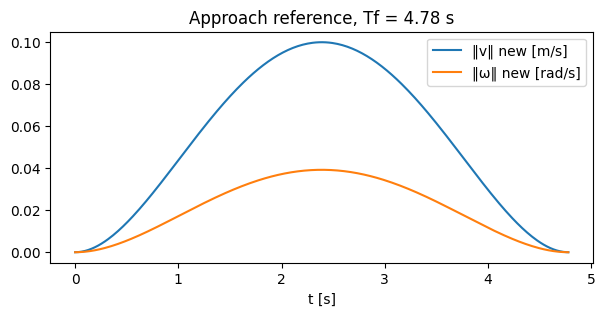

old law at t=0 (before the ramp): ‖v‖ = 0.76 m/s, ‖ω‖ = 0.20 rad/s  (new peak: 0.10 m/s, 0.30 rad/s)


In [9]:
from pandaSim.control.backends import SimBackend
from pandaSim.control.primitive_executor import approach_reference, contact_pose, run_pivot, check_profile

fk = lambda q: contact_pose(robot, q)
q0 = robot.qr.copy()
ref, Tf_app = approach_reference(fk, fk(q0), T_wd, K_e=0.0)          # feed-forward part only
tt = np.linspace(0, Tf_app, 300)
Vs = np.array([ref(ti, q0) for ti in tt])
e0 = pose_error_twist(fk(q0), T_wd)
old_v0 = np.linalg.norm(3.0 * e0[3:])                                   # old p_servo gains (tests/rtb.ipynb): 3 (v), 2 (ω)
old_w0 = np.linalg.norm(2.0 * e0[:3])
plt.figure(figsize=(7, 3))
plt.plot(tt, np.linalg.norm(Vs[:, 3:], axis=1), label="‖v‖ new [m/s]")
plt.plot(tt, np.linalg.norm(Vs[:, :3], axis=1), label="‖ω‖ new [rad/s]")
plt.xlabel("t [s]"); plt.legend(); plt.title(f"Approach reference, Tf = {Tf_app:.2f} s"); plt.show()
print(f"old law at t=0 (before the ramp): ‖v‖ = {old_v0:.2f} m/s, ‖ω‖ = {old_w0:.2f} rad/s  (new peak: 0.10 m/s, 0.30 rad/s)")

{'mode': 'free', 'ok': True, 'segments': [('approach', True, None), ('pivot', True, None)], 's_reached': 1.0, 'pos_err_mm': np.float64(0.1298814566568838), 'rot_err_deg': np.float64(0.0006981764601086255), 'pivot_point_drift_mm': np.float64(0.1298123917815897)}
speed gate: True  max |θ̇|/(0.8·limit): [0.011 0.204 0.01  0.215 0.013 0.17  0.006]
max |θ̈| / kMaxJointAcceleration: [0.001 0.045 0.001 0.02  0.001 0.015 0.   ]
gripper events: [('open', 0.0, True), ('grasp', 4.77799999999993, True), ('release', 9.77800000000002, True)]


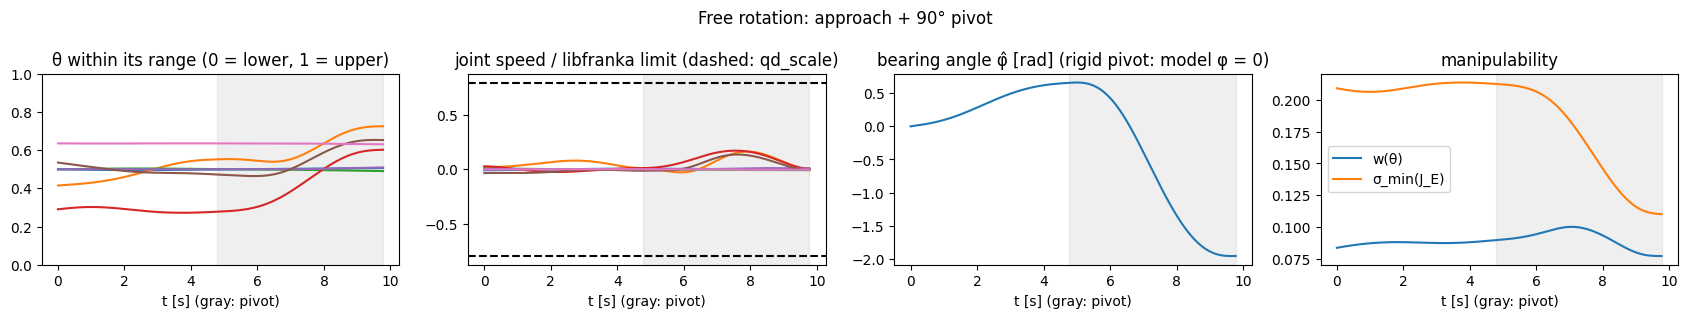

In [10]:
def summarize(log, name):
    a = log.arrays()
    out = dict(mode=name, ok=log.ok, segments=[(s["name"], s["ok"], s["cause"]) for s in log.segments])
    piv = a["segment"] == 1
    if piv.any():
        seg = log.segments[1]
        q_start = np.r_[a["theta"][piv][0], a["phi"][piv][0]]
        q_end = np.r_[a["theta"][piv][-1], a["phi"][piv][-1]]
        T0, T1 = fk(q_start), fk(q_end)
        s_end = time_scaling(seg["t_end"] - seg["t0"], seg["Tf"])[0]
        E = np.linalg.inv(planned_pose(q_axis, s_axis, theta, T0, s_end)) @ T1     # vs the plan at the same s
        D = T1 @ np.linalg.inv(T0)
        out.update(s_reached=s_end, pos_err_mm=np.linalg.norm(E[:3, 3]) * 1e3,
                   rot_err_deg=np.degrees(pr.axis_angle_from_matrix(E[:3, :3])[3]),
                   pivot_point_drift_mm=np.linalg.norm(D[:3, :3] @ q_axis + D[:3, 3] - q_axis) * 1e3)
    return out

def manip(log):
    a = log.arrays(); k = np.arange(0, len(a["t"]), 20)
    w, smin = [], []
    for i in k:
        J = ets.jacobe(np.r_[a["theta"][i], a["phi"][i]])[:, :7]
        w.append(np.sqrt(np.linalg.det(J @ J.T))); smin.append(np.linalg.svd(J, compute_uv=False)[-1])
    return a["t"][k], np.array(w), np.array(smin)

def plot_run(log, title):
    a = log.arrays(); t = a["t"]
    lo, hi = robot.qlim[0, :7], robot.qlim[1, :7]
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
    ax[0].plot(t, (a["theta"] - lo) / (hi - lo)); ax[0].set(title="θ within its range (0 = lower, 1 = upper)", ylim=(0, 1))
    ax[1].plot(t, a["qd"][:, :7] / FER_QD_MAX); ax[1].axhline(0.8, c="k", ls="--"); ax[1].axhline(-0.8, c="k", ls="--")
    ax[1].set(title="joint speed / libfranka limit (dashed: qd_scale)")
    ax[2].plot(t, a["phi"]); ax[2].set(title="bearing angle φ̂ [rad] (rigid pivot: model φ = 0)")
    tm, w, smin = manip(log)
    ax[3].plot(tm, w, label="w(θ)"); ax[3].plot(tm, smin, label="σ_min(J_E)"); ax[3].legend(); ax[3].set(title="manipulability")
    for axi in ax:
        for s in log.segments[1:]:
            axi.axvspan(s["t0"], s["t_end"], color="gray", alpha=0.12)
        axi.set_xlabel("t [s] (gray: pivot)")
    fig.suptitle(title); plt.tight_layout(); plt.show()

log_free = run_pivot(SimBackend(robot.qr[:7]), robot, T_wd, pivot, free_rotation=True, grasp=dict(width=0.065, force=20))
print(summarize(log_free, "free"))
prof = check_profile(log_free)
print("speed gate:", prof["vel_ok"], " max |θ̇|/(0.8·limit):", prof["vel_ratio"].round(3))
print("max |θ̈| / kMaxJointAcceleration:", prof["acc_ratio"].round(3))
print("gripper events:", log_free.events)
plot_run(log_free, "Free rotation: approach + 90° pivot")

{'mode': 'rigid', 'ok': False, 'segments': [('approach', True, None), ('pivot', False, 'infeasible QP')], 's_reached': 0.29962946397607226, 'pos_err_mm': np.float64(0.30206656727333714), 'rot_err_deg': np.float64(0.04580483829511523), 'pivot_point_drift_mm': np.float64(0.07035286492611623)}


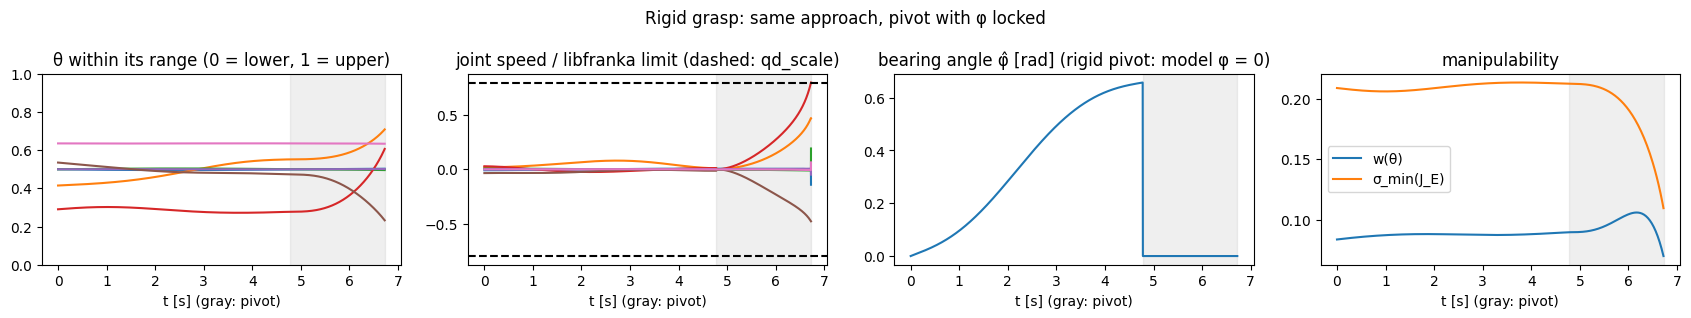

In [11]:
log_rigid = run_pivot(SimBackend(robot.qr[:7]), robot, T_wd, pivot, free_rotation=False, grasp=dict(width=0.065, force=20))
print(summarize(log_rigid, "rigid"))
plot_run(log_rigid, "Rigid grasp: same approach, pivot with φ locked")

{'mode': 'rigid + slack', 'ok': True, 'segments': [('approach', True, None), ('pivot', True, None)], 's_reached': 1.0, 'pos_err_mm': np.float64(366.47680943725), 'rot_err_deg': np.float64(3.235999155495752), 'pivot_point_drift_mm': np.float64(352.93542734591654)}


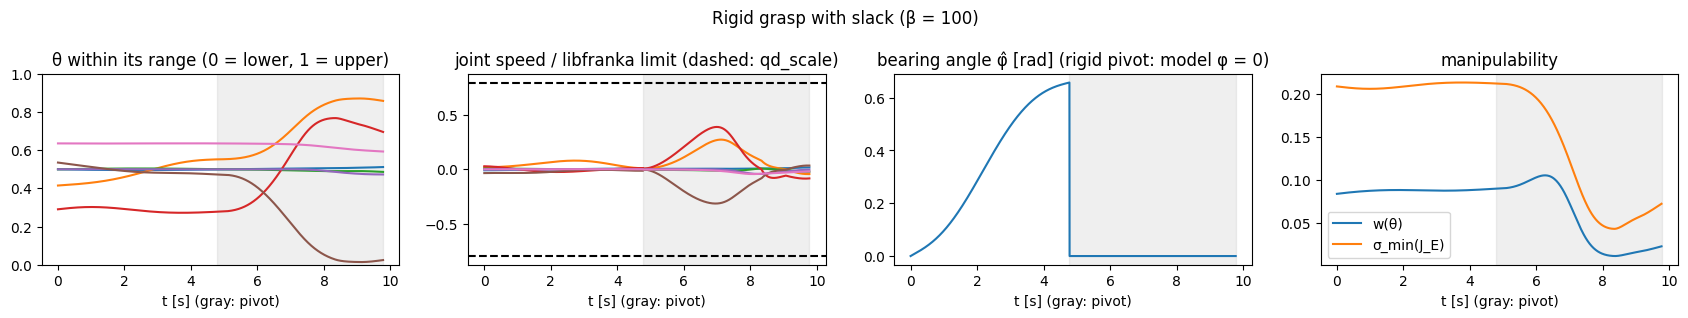

In [12]:
log_slack = run_pivot(SimBackend(robot.qr[:7]), robot, T_wd, pivot, free_rotation=False, qp=dict(slack=100.0),
                      grasp=dict(width=0.065, force=20))
print(summarize(log_slack, "rigid + slack"))
plot_run(log_slack, "Rigid grasp with slack (β = 100)")

In [13]:
rows = [summarize(l, n) for l, n in ((log_free, "free"), (log_rigid, "rigid (hard)"), (log_slack, "rigid + slack"))]
print(f"{'mode':15s} {'completed':>9s} {'s reached':>9s} {'pos err [mm]':>12s} {'rot err [°]':>11s} {'pivot drift [mm]':>16s}  stop cause")
for r in rows:
    cause = [c for _, ok, c in r["segments"] if not ok]
    print(f"{r['mode']:15s} {str(r['ok']):>9s} {r['s_reached']:9.2f} {r['pos_err_mm']:12.2f} {r['rot_err_deg']:11.3f} "
          f"{r['pivot_point_drift_mm']:16.2f}  {cause[0] if cause else '-'}")

mode            completed s reached pos err [mm] rot err [°] pivot drift [mm]  stop cause
free                 True      1.00         0.13       0.001             0.13  -
rigid (hard)        False      0.30         0.30       0.046             0.07  infeasible QP
rigid + slack        True      1.00       366.48       3.236           352.94  -


**Reading the result.** With the same grasp and the same approach:

- **Free rotation** follows the planned pivot (sub-millimetre), with ~1 rad margin to every joint
  limit; the bearing turns by roughly 110° during the pivot.
- **Rigid, hard equality** stops part-way (infeasible QP), here at s ≈ 0.3: joint 4 reaches its speed
  limit while σ_min falls (the speed needed grows steeply near a singularity). In Phase 3 (start from
  inverse kinematics instead of the approach) the stopping point moved only from s = 0.35 to 0.44 when
  the pivot was slowed from 5 s to 20 s, while manipulability and σ_min collapse and all joints stay
  ≥ 0.6 rad from their limits: a **singularity**, the planar 3R example of the manuscript on the Panda.
- **Rigid + slack** (Haviland-style) always completes, but by not doing the screw motion: here the
  contact frame ends 0.37 m from the plan and the pivot edge would have to move 0.35 m, i.e. the
  edge slides or lifts instead of pivoting. This answers the
  reviewer question "would a slack QP have been enough?"

This is one grasp and one object; Phase 5 runs the systematic comparison (failure cause, joint
margins, manipulability, task error, sweep of the rigid grasp angle about `n`).

## 5. Optional: live viewer and replay (`RUN_VIEWER = True`)

`LiveViewer` runs Swift in a **separate process**; the loop only writes the joint vector into shared
memory (< 5 µs, no lock), the viewer draws at 30 Hz and carries the object after the grasp. Swift's
~9 ms step therefore never blocks the control loop. Measured: tick p99 0.29 ms without, 0.39 ms with
the viewer (CPU contention only). `replay` plays a saved log back (videos). Scripts that start the
viewer need an `if __name__ == "__main__":` guard (spawn); a notebook does not.

In [14]:
from pandaSim.control.viewer import LiveViewer, replay

objects = [dict(type="cuboid", scale=BOX, pose=T_w_obj, color="blue"),
           dict(type="cuboid", scale=[0.3, 0.3, BASE_Z], pose=sm.SE3(-0.04, 0, BASE_Z / 2).A, color="gray")]
log_path = Path(tempfile.gettempdir()) / "pandasim_free_run.npz"
log_free.save(log_path)

class PacedSim(SimBackend):
    # real-time pacing like PandaContext, so the live view shows the motion at its real speed
    def tick(self):
        self._next = getattr(self, "_next", time.perf_counter()) + self.dt
        while time.perf_counter() < self._next:
            pass
        return super().tick()

if RUN_VIEWER:
    with LiveViewer(robot.base.A, objects, q0=robot.qr) as viewer:
        time.sleep(8)                      # Swift and the browser start
        log_live = run_pivot(PacedSim(robot.qr[:7]), robot, T_wd, pivot, grasp=dict(width=0.065),
                             viewer=viewer, T_w_obj=T_w_obj)
        a = log_live.arrays()
        print(f"live run ok={log_live.ok}; tick p50 {np.median(a['tick_time'])*1e3:.3f} ms, p99 {np.percentile(a['tick_time'], 99)*1e3:.3f} ms")
    # replay(log_path, robot.base.A, objects)    # offline playback of the saved run
else:
    print("RUN_VIEWER is False; saved the free run to", log_path)

RUN_VIEWER is False; saved the free run to /tmp/pandasim_free_run.npz


## 6. Optional: read-only FER check (`RUN_HARDWARE = True`, be at the robot)

Sends **no motion commands**: connects (libfranka version, FCI), reads the state once and 200 times
for timing, reads the gripper if present, then locks the brakes through Desk (credentials from
`pandaSim/.env`). Same code as `python experiments/check_connection.py 172.16.0.2 --base-z 0.013`.

Findings on 2026-10-29: link 0 % loss, 0.23 ms RTT; the 0.8.0 build connects; `kIdle` after unlocking;
no errors; `F_ext` ≤ 0.3 N, `τ_ext` ≤ 0.25 Nm at rest; model fingertip 0.30 m forward, 0.50 m above
the table. `panda.q` and `get_state()` both take ~1.0 ms with no controller running (each waits for the
next state packet), so the backend reads the state **once per tick**. Real-time scheduling was refused
because only user `mahi` had an `rtprio` limit; now granted.

In [15]:
import os, resource

print("rtprio limit:", resource.getrlimit(resource.RLIMIT_RTPRIO)[0])
if RUN_HARDWARE:
    import panda_py
    from panda_py import libfranka
    from check_connection import report, desk_credentials, lock_brakes     # experiments/ is the working directory

    rt = libfranka.RealtimeConfig.kEnforce if resource.getrlimit(resource.RLIMIT_RTPRIO)[0] > 0 else libfranka.RealtimeConfig.kIgnore
    panda = panda_py.Panda(ROBOT_IP, realtime_config=rt)
    try:
        gripper = libfranka.Gripper(ROBOT_IP)
    except RuntimeError as e:
        gripper = None; print("gripper not reachable:", e)
    report(panda, gripper, robot)
    creds = desk_credentials(Path.cwd().parent / ".env")
    if creds:
        lock_brakes(panda_py.Desk(ROBOT_IP, *creds, platform="panda")); print("brakes locked")
else:
    print("RUN_HARDWARE is False: skipped")

rtprio limit: 99
RUN_HARDWARE is False: skipped


## 7. Findings so far and next steps

- **Body twist, once.** The pivot twist of `{c}` is constant in `{c}`; computed once at the grasp,
  scaled by `ṡ(t)`. Matches the old generator exactly and the numerical body twist of ScLERP.
- **QP as in Sec. 6.** The previous controller differed from the manuscript (φ centred, damped and in
  the manipulability term). `ContactQP` fixes this, uses the real libfranka limits, and solves in
  ~0.11 ms (p99 < 0.2 ms), so a 1 kHz loop is realistic. libfranka's C++ thread is the real-time
  loop; the Python rate is configurable.
- **Approach without an output ramp.** A time-scaled screw reference with small feedback replaces
  the ramp: zero velocity at both ends, speed set in advance.
- **First dexterity result.** Free rotation completes the 90° pivot; the rigid grasp runs into a
  singularity part-way (s ≈ 0.3–0.45 depending on start and speed); slack completes only by leaving
  the screw motion.
- **Hardware.** Connection, state, and limits checked (read-only); real-time permission now granted.

**Next.** Phase 5: YAML configs and `run_primitive.py` (sim | real), offline analysis and the
systematic free / rigid / slack ablation, observability check of the grasp. Phase 6 (with you at the
robot): CPU governor `performance`, gripper connected, first zero-velocity hold (also measures the
state read cost with a controller running), then the run ladder.